<a href="https://colab.research.google.com/github/thecodingAdi/ai-ml-playground/blob/main/Unsupervised_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#KMeans clustering

In [16]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [17]:
X ,y_true = make_blobs(n_samples=300, centers=3, cluster_std=0.60, random_state=42)


In [18]:
df = pd.DataFrame(X, columns=['feature1', 'feature2'])
df.head()


,feature1,feature2
0,-7.155244,-7.390016
1,-7.395875,-7.110843
2,-2.015671,8.281780
3,4.509270,2.632436
4,-8.102502,-7.484961


In [19]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

In [20]:
inertia = []
K_range = range(1,11)

In [21]:
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

In [22]:
inertia

[599.9999999999997,
 178.65671614695478,
 6.775066760799564,
 5.767530252280139,
 4.722401665493833,
 4.344605803073936,
 4.141728955615087,
 3.2562398432313193,
 2.9977535420822266,
 2.5997714738604842]

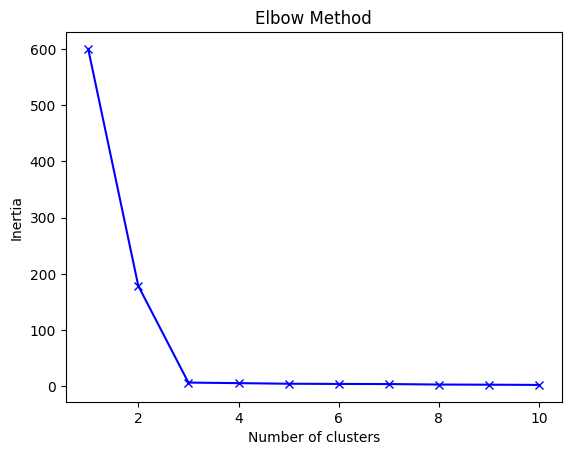

In [23]:
plt.plot(K_range, inertia, 'bx-')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

In [24]:
kmeans_final = KMeans(n_clusters=3, random_state=42)

In [25]:
cluster_labels = kmeans_final.fit_predict(X_scaled)

In [26]:
cluster_labels

array([1, 1, 0, 2, 1, 2, 0, 2, 0, 0, 0, 2, 0, 0, 1, 0, 1, 2, 0, 0, 0, 0,
       2, 1, 0, 1, 1, 2, 2, 0, 0, 0, 1, 0, 1, 0, 1, 2, 1, 2, 2, 0, 1, 2,
       0, 0, 1, 2, 1, 2, 2, 1, 1, 0, 1, 2, 1, 0, 2, 0, 1, 2, 2, 1, 1, 2,
       2, 1, 1, 0, 2, 1, 1, 0, 0, 1, 1, 2, 0, 2, 0, 0, 1, 0, 2, 1, 1, 0,
       2, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 1, 2, 0, 2, 0, 0, 0, 0, 0, 2, 1,
       2, 0, 0, 0, 0, 2, 1, 2, 1, 2, 2, 2, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0,
       0, 0, 0, 2, 2, 1, 0, 1, 0, 0, 1, 0, 2, 2, 2, 0, 2, 0, 0, 1, 2, 1,
       0, 2, 2, 1, 1, 0, 0, 1, 1, 1, 0, 1, 2, 0, 0, 0, 0, 0, 2, 0, 2, 2,
       2, 0, 2, 2, 1, 0, 1, 2, 2, 1, 2, 0, 2, 2, 1, 1, 2, 1, 2, 2, 2, 2,
       0, 1, 0, 0, 2, 2, 0, 2, 1, 1, 2, 0, 0, 1, 2, 2, 1, 1, 1, 1, 0, 1,
       1, 2, 1, 1, 0, 2, 1, 1, 2, 0, 0, 1, 0, 1, 2, 2, 1, 2, 1, 1, 1, 2,
       2, 0, 1, 2, 2, 2, 1, 2, 1, 2, 1, 2, 2, 1, 2, 0, 1, 0, 0, 0, 1, 0,
       2, 2, 1, 2, 2, 0, 0, 2, 2, 2, 1, 1, 1, 0, 0, 0, 2, 2, 2, 2, 1, 2,
       1, 2, 2, 1, 0, 2, 2, 0, 1, 0, 2, 0, 1, 1], d

In [27]:
df['cluster'] = cluster_labels

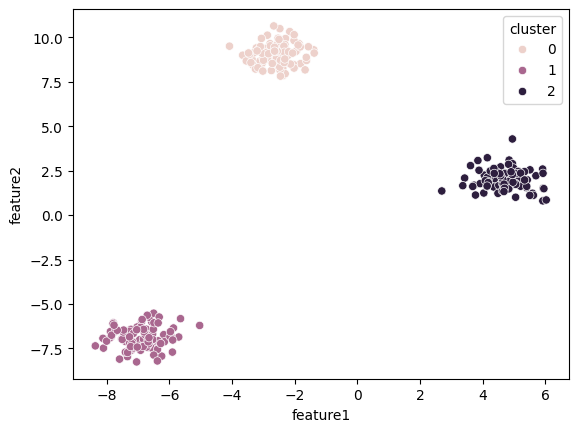

In [28]:
sns.scatterplot(data=df, x='feature1', y='feature2', hue='cluster')
plt.show()
#

#DB Scan

In [31]:
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN, KMeans

In [30]:
X, y_true = make_moons(n_samples=200, noise=0.05, random_state=42)

In [32]:
df = pd.DataFrame(X, columns=['feature1', 'feature2'])
df.head()

,feature1,feature2
0,-1.020690,0.105518
1,0.905826,0.457858
2,0.618422,0.757086
3,1.227707,-0.425185
4,0.329356,-0.206946


In [33]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

In [39]:
df['KMeans_cluster'] = KMeans(n_clusters=2, random_state=42).fit_predict(X_scaled)

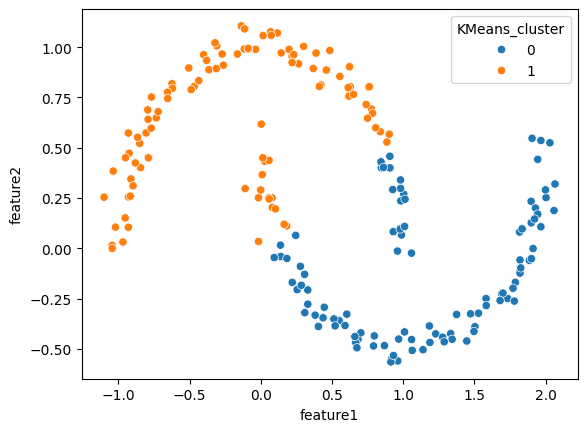

In [40]:
sns.scatterplot(data=df, x='feature1', y='feature2', hue='KMeans_cluster')
plt.show()

In [50]:
dbscan = DBSCAN(eps=0.3, min_samples=5)
dbscan_labels = dbscan.fit_predict(X_scaled)

In [51]:
df['dbscan_cluster'] = dbscan_labels

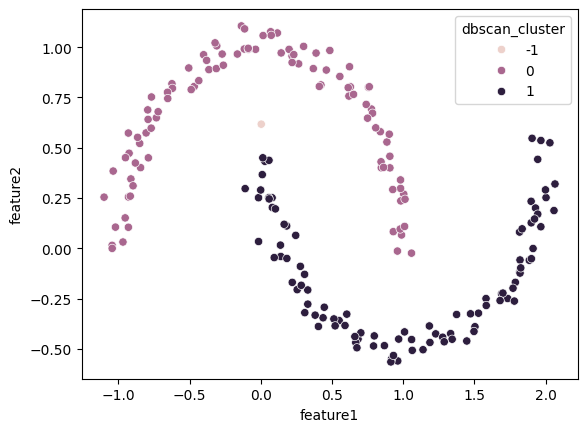

In [52]:
sns.scatterplot(data=df, x='feature1', y='feature2', hue='dbscan_cluster')
plt.show()

# PCADimensions
Dimensionality reduction

In [53]:
from sklearn.decomposition import PCA

In [55]:
X, y = make_blobs(n_samples=500, n_features=5,centers=3, random_state=42)

In [56]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [57]:
X_scaled

array([[-1.11153121,  0.74311336,  0.16773367, -1.55904122, -0.83289732],
       [-0.72244227,  0.65538432,  0.16888529, -1.12237371, -0.68340712],
       [ 0.96505379,  0.5116106 , -1.20417155,  0.37035788, -0.76842168],
       ...,
       [ 0.04570329, -1.28930429,  0.78237239,  0.80244161,  1.80930723],
       [ 1.23386097,  0.74025076, -0.35256145,  0.50148642, -0.82565212],
       [-0.5585766 , -1.55552823,  1.16398027,  1.19407709,  1.34862446]])

In [58]:
pca = PCA(n_components=2)
X_pca_reduced = pca.fit_transform(X_scaled)

In [59]:
X_pca_reduced

array([[-1.06393431e+00, -1.94087733e+00],
       [-8.81033639e-01, -1.38741787e+00],
       [-1.36561474e+00,  1.20255029e+00],
       [ 1.89627034e+00,  3.49468207e-01],
       [-6.55599835e-01, -1.86087350e+00],
       [-1.31408934e+00,  1.19020890e+00],
       [-1.41161440e+00,  1.77296243e+00],
       [ 3.03334762e+00,  1.99808599e-01],
       [ 1.43808194e+00,  8.32782920e-01],
       [-7.84446973e-01,  1.08539575e+00],
       [-1.84087620e+00,  1.77507069e+00],
       [-1.25748239e+00,  1.94677873e+00],
       [ 2.03817880e+00,  3.34185885e-01],
       [-9.81094696e-01, -1.66670684e+00],
       [-6.57577242e-01, -1.37749035e+00],
       [-1.22454737e+00, -1.88557416e+00],
       [ 2.56474500e+00, -2.98165999e-01],
       [ 2.09097393e+00,  2.41405852e-01],
       [-1.62211374e+00,  2.33100481e+00],
       [-1.29987280e+00, -1.70905025e+00],
       [-1.79433540e+00,  1.34540469e+00],
       [ 1.91581950e+00,  3.56156008e-01],
       [ 1.98368765e+00,  5.23027054e-01],
       [-4.

In [63]:
df_pca = pd.DataFrame(X_pca_reduced, columns=['PC1', 'PC2'])
df_pca['label'] = y

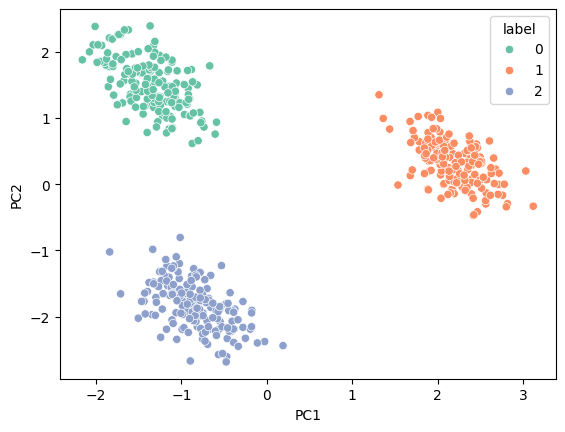

In [65]:
sns.scatterplot(data=df_pca, x='PC1', y='PC2', hue='label',palette='Set2')
plt.show()